# Which Waze users are about to churn? A transparent baseline with softmax regression and k-nearest neighbors

**Governing question.** Using one month of app activity plus lifetime totals, how well can we rank Waze users by their risk of churning that month—and how many churners would a retention campaign of a given size actually reach?

**Intended user.** A Waze product manager who must decide *which* users receive a retention message (an in-app prompt or email). Outreach is cheap but not free: every message to a user who would have stayed costs attention and goodwill. A useful answer tells the PM how many churners a campaign reaches for a given outreach budget, and which behaviors the risk score relies on.

**Why rebuild this.** This project revisits an earlier churn analysis (RCEL 506) that compared library decision trees, random forests, and XGBoost. Here every model is student-implemented and verified, the test set is opened once after all choices are frozen, results carry uncertainty, and the analysis starts from simple, transparent models so later, more complex models must earn their place.

**Road map.** §1 contract → §2 data boundary → §3 purposeful exploration → §4 evaluation design → §5 the two models and the threshold → §6 verification → §7 cross-validated selection → §8 one sealed test evaluation → §9 failure analysis → §10 decision and next steps.

## 1. Investigation contract

| Item | Decision |
| --- | --- |
| Observation unit | One Waze user (14,299 labeled users) |
| Target | `churned` = 1 if the user churned during the observed month, else 0 |
| Features | 10 usage measurements and a device indicator (`is_iphone`), all from the package's `FEATURE_COLUMNS` |
| Kind of work | Predictive ranking of current users; **not** causal—low activity is associated with churn, it does not cause it |
| Cost of errors | A missed churner is a lost user; a false alarm is an unnecessary message. We treat missing a churner as more costly (F2 metric, §4) |
| Non-goals | Forecasting churn months ahead; explaining *why* users leave; any decision about individual users without human review |

**Information available at prediction time—an important caveat.** The month-level activity columns (`activity_days`, `driving_days`, `sessions`, …) describe the *same month* in which churn was recorded. A user who stops using Waze mid-month therefore both churns and shows low activity. The model can rank users whose disengagement is already visible; it cannot tell us how *early* churn is predictable. We report that limitation rather than claim early warning.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    fbeta_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from dsm_project.algorithms import MajorityClassifier, create_student_algorithm
from dsm_project.algorithms.student.logistic import cross_entropy_objective
from dsm_project.config import load_config
from dsm_project.data.waze import WazeChurnAdapter
from dsm_project.evaluation import (
    ThresholdedClassifier,
    bootstrap_metric_interval,
    choose_threshold,
    precision_recall_at,
)
from dsm_project.experiments import evaluate_supervised_estimator, split_supervised_task

CONFIG_PATH = Path("configs/waze.toml")
TASK_KEY = "classification"

config = load_config(CONFIG_PATH)
dataset, report = WazeChurnAdapter().load_with_report(config)
task = dataset.tasks[TASK_KEY]
frame = dataset.observations

print(report)
print("features:", task.feature_columns)

WazeDataReport(raw_rows=14999, unlabeled_rows=700, modeled_rows=14299, churn_rate=0.17735505979439123, total_below_month_sessions=18, implausible_speed_rows=3370)
features: ('sessions', 'drives', 'total_sessions', 'n_days_after_onboarding', 'total_navigations_fav1', 'total_navigations_fav2', 'driven_km_drives', 'duration_minutes_drives', 'activity_days', 'driving_days', 'is_iphone')


## 2. Data provenance and the data boundary

- **Source.** A synthetic user-level dataset created by Waze with Google for churn analysis and distributed on Kaggle. Synthetic means patterns may resemble real behavior, but nothing here is evidence about actual Waze users. Full details and the license status are in `docs/DATASET_CARD.md`; the CSV is kept out of git until redistribution terms are confirmed.
- **Version.** The adapter refuses to load a file whose SHA-256 differs from the one recorded in `configs/waze.toml`, so every number below refers to one exact file.
- **What the boundary does** (`dsm_project.data.waze`): checks every column, type, and range (non-negative counts, at most 31 days per month, `driving_days ≤ activity_days`, `drives ≤ sessions`, known labels and devices); drops the **700 users with no label**; and encodes `churned` and `is_iphone`.

The report above records what was removed or flagged. Two kinds of flagged rows remain in the data on purpose:

- 18 users report fewer lifetime sessions than sessions this month, which is logically impossible; and
- 3,370 users (24%) imply an average driving speed above 200 km/h when `driven_km_drives` is divided by `duration_minutes_drives`.

These are artifacts of the synthetic generator. We keep the rows—dropping a quarter of the data on a definition we cannot verify would itself bias the sample—but treat the kilometer and duration columns as weak, noisy measurements.

**Are the dropped users different?** If unlabeled users differed systematically, dropping them would bias the sample. The cell below compares them with labeled users.

In [2]:
raw = pd.read_csv(config.root / config.dataset["path"])
unlabeled = raw["label"].isna()
comparison = pd.DataFrame(
    {
        "labeled (median)": raw.loc[~unlabeled, ["sessions", "drives", "activity_days",
                                                 "n_days_after_onboarding"]].median(),
        "unlabeled (median)": raw.loc[unlabeled, ["sessions", "drives", "activity_days",
                                                  "n_days_after_onboarding"]].median(),
    }
)
comparison.loc["iPhone share"] = [
    (raw.loc[~unlabeled, "device"] == "iPhone").mean(),
    (raw.loc[unlabeled, "device"] == "iPhone").mean(),
]
display(comparison.round(3))

,labeled (median),unlabeled (median)
sessions,56.000,56.000
drives,48.000,47.500
activity_days,16.000,15.000
n_days_after_onboarding,1749.000,1650.500
iPhone share,0.645,0.639


Unlabeled users look like everyone else on activity, tenure, and device, so dropping them is unlikely to bias the sample (though we cannot rule out differences on unmeasured traits).

## 3. Purposeful exploration

Three questions shape the modeling plan:

1. **How rare is churn?** This fixes the baseline and the metric.
2. **Which behaviors move with churn, and how strongly?** This tells us whether a simple model could work and which features it will lean on.
3. **How skewed are the features?** Both models use distances or a single gradient step size, so scale and outliers matter.

churn rate  Android: 0.176  iPhone: 0.178


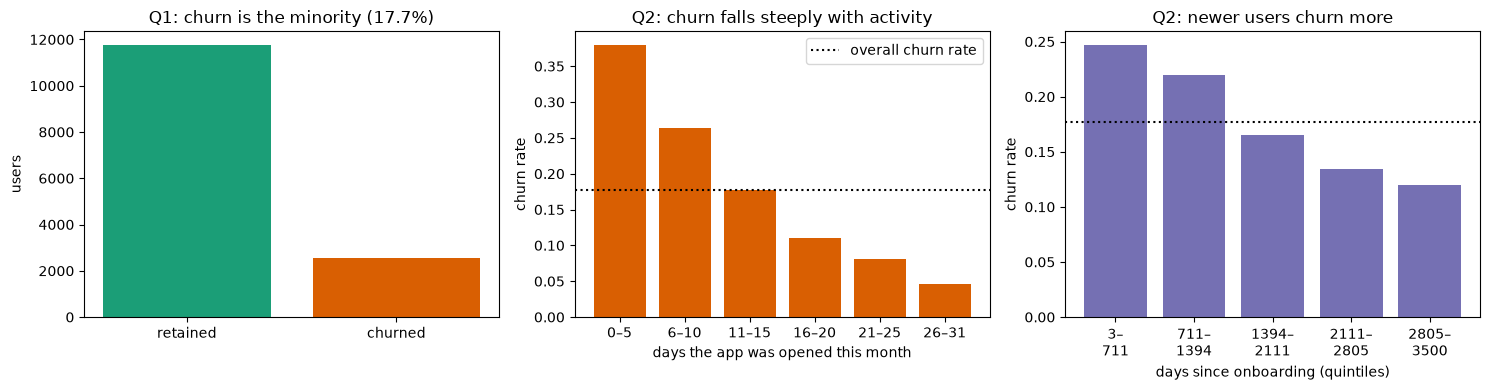

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

rate = frame["churned"].mean()
axes[0].bar(["retained", "churned"], frame["churned"].value_counts().sort_index().values,
            color=["#1b9e77", "#d95f02"])
axes[0].set(ylabel="users", title=f"Q1: churn is the minority ({rate:.1%})")

activity = frame.groupby(pd.cut(frame["activity_days"], [-1, 5, 10, 15, 20, 25, 31]),
                         observed=True)["churned"].mean()
axes[1].bar(["0–5", "6–10", "11–15", "16–20", "21–25", "26–31"], activity.values,
            color="#d95f02")
axes[1].axhline(rate, color="black", linestyle=":", label="overall churn rate")
axes[1].set(xlabel="days the app was opened this month", ylabel="churn rate",
            title="Q2: churn falls steeply with activity")
axes[1].legend()

tenure = frame.groupby(pd.qcut(frame["n_days_after_onboarding"], 5), observed=True)["churned"].mean()
axes[2].bar([f"{int(b.left)}–\n{int(b.right)}" for b in tenure.index], tenure.values,
            color="#7570b3")
axes[2].axhline(rate, color="black", linestyle=":")
axes[2].set(xlabel="days since onboarding (quintiles)", ylabel="churn rate",
            title="Q2: newer users churn more")
plt.tight_layout()

device = frame.groupby("is_iphone")["churned"].mean()
print(f"churn rate  Android: {device[0]:.3f}  iPhone: {device[1]:.3f}")

**Q1.** About 18% of users churned. A model that predicts "retained" for everyone is 82% accurate yet useless, so accuracy is the wrong metric (§4).

**Q2.** Churn falls steadily from 38% among users active on 5 or fewer days to under 5% among users active on more than 25 days, and newer users churn about twice as often as the longest-tenured ones. Device makes no difference. These are strong, roughly *monotone* relationships, which favors a linear-in-features model like softmax regression. They also preview the main failure risk: users who churn *while still active* will look like retained users.

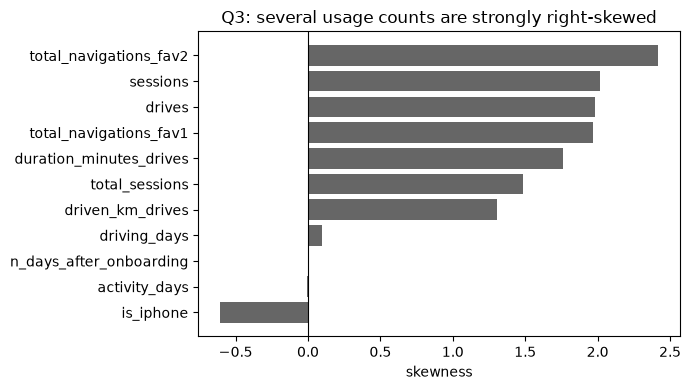

In [4]:
skew = frame.loc[:, task.feature_columns].skew().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(skew.index, skew.values, color="#666666")
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="skewness", title="Q3: several usage counts are strongly right-skewed")
plt.tight_layout()

**Q3.** Session, drive, distance, and navigation counts have long right tails. Features are standardized inside every pipeline. Because heavy tails could distort distances, we also test a `log1p` transform as a **candidate** in §7 rather than assuming it helps.

## 4. Evaluation design

- **Sealed test set.** `split_supervised_task` draws one stratified 75/25 split (seed 438 in the config): **10,724 development users** and **3,575 sealed test users**, both about 17.7% churn. The test users are scored once, in §8.
- **Selection.** All choices—preprocessing, $\lambda$, class weighting, $k$, and the decision threshold—are made with 5-fold stratified cross-validation on the development users. We keep each user's **out-of-fold** probability, predicted by a model that never saw that user.
- **Baseline.** `MajorityClassifier` predicts "retained" for everyone. Its ranking is no better than random, so its average precision equals the churn rate.
- **Ranking metric (model selection).** *Average precision* (AP) summarizes the precision–recall curve across all thresholds:

$$
\text{AP} = \sum_{j} (R_j - R_{j-1})\,P_j,
$$

where $P_j$ and $R_j$ are precision and recall when flagging the top $j$ users. It ranges from the churn rate (random ranking) to 1 (perfect ranking).

- **Decision metric (threshold).** Flagging a user is a yes/no action, so we also need a threshold $t$: flag user $i$ when $\hat p_i \ge t$. We choose $t$ to maximize

$$
F_\beta = \frac{(1+\beta^2)\,P\,R}{\beta^2 P + R}, \qquad \beta = 2,
$$

which counts recall (churners reached) twice as heavily as precision (messages well spent). Because outreach budgets are often fixed in practice, we also report precision and recall when flagging the riskiest 10%, 20%, and 30% of users.

**Selection rule, fixed before looking at results.** Pick the highest out-of-fold AP within each model family. Differences under 0.005 AP count as ties, broken toward the simpler option: stronger regularization, no class weighting, no log transform, larger $k$.

In [5]:
split = split_supervised_task(dataset, config, task_name=TASK_KEY)
dev_x, dev_y = split.train_features, split.train_targets
print(f"development users: {len(dev_x):,} (churn {dev_y.mean():.3f}) | "
      f"sealed test users: {len(split.test_features):,} (churn {split.test_targets.mean():.3f})")

development users: 10,724 (churn 0.177) | sealed test users: 3,575 (churn 0.177)


## 5. The models and the threshold

Both models were derived and verified in notebook 01 (`notebooks/01-wine-cultivar-softmax-vs-knn.ipynb`); here we summarize what changes for churn.

**Softmax regression with two classes** reduces to logistic regression. With standardized features $x_i$ and score $z_i = x_i^\top w + b$, the churn probability is $\hat p_i = 1/(1+e^{-z_i})$. Each coefficient is the change in the log-odds of churn per standard deviation of its feature, which makes the model directly readable by a PM.

**Class weighting.** Rare churners contribute little to the average loss, so we optionally give each row a weight $s_i$ and minimize

$$
J(W,b) = -\frac{1}{S}\sum_{i=1}^{n}\sum_{k} s_i\,Y_{ik}\log p_{ik} + \frac{\lambda}{2}\lVert W\rVert_F^2, \qquad S=\sum_i s_i .
$$

With `class_weight="balanced"`, $s_i = n/(K n_{k})$ for a user in class $k$, so churners and retained users carry equal total weight. The gradient keeps the same form as before, with each residual row multiplied by $s_i$.

**k-nearest neighbors** estimates churn risk as the fraction of churners among a user's $k$ most similar users in standardized feature space: $\hat p(x) = \frac{1}{k}\sum_{j\in N_k(x)} y_j$. With 10,000+ users, the student implementation scores queries in memory-bounded blocks, producing identical results to scoring everything at once.

**Why the threshold matters more than weighting.** Weighting rescales the predicted probabilities, but if the *ordering* of users barely changes, choosing a threshold on the unweighted model reaches the same decisions. §7 tests this directly.

## 6. Student implementation and verification

| Component | Package location | Key tests |
| --- | --- | --- |
| `SoftmaxRegression(class_weight=...)` | `src/dsm_project/algorithms/student/logistic.py` | weighted gradient matches finite differences; weight 3 on a class equals tripling its rows; matches scikit-learn's balanced `LogisticRegression` probabilities to $10^{-5}$ |
| `KNearestNeighborsClassifier` (blocked) | `src/dsm_project/algorithms/student/neighbors.py` | blocked and unblocked neighbor search agree exactly; matches scikit-learn's brute-force k-NN |
| `choose_threshold`, `ThresholdedClassifier` | `src/dsm_project/evaluation/thresholds.py` | finds the brute-force F-beta optimum; tie rule; F-beta equals scikit-learn's `fbeta_score` |
| `WazeChurnAdapter` | `src/dsm_project/data/waze.py` | rejects nine kinds of structural defect; runs in CI on a constructed fixture |

One verification finding is worth recording. For **two** classes, scikit-learn's logistic regression fits one weight vector $w$, while softmax fits one per class ($w_0, w_1$). At the softmax optimum $w_0 = -w_1 = -w/2$, so the ridge term $\frac{\lambda}{2}(\lVert w_0\rVert^2+\lVert w_1\rVert^2) = \frac{\lambda}{4}\lVert w\rVert^2$ is *half* the binary penalty. The matching scikit-learn setting is therefore $C = 2/(n\lambda)$ rather than $1/(n\lambda)$; the differential test failed until this was derived, and the probabilities now agree.

As a live check, the weighted gradient used on this data matches central finite differences:

In [6]:
rng = np.random.default_rng(0)
x_small = rng.normal(size=(20, 3))
y_small = np.eye(2)[rng.integers(0, 2, size=20)]
w0, b0, row_weights, h = rng.normal(size=(3, 2)), rng.normal(size=2), rng.uniform(0.5, 4, 20), 1e-6
_, gradient, _ = cross_entropy_objective(w0, b0, x_small, y_small, 0.1, row_weights)
numeric = np.zeros_like(w0)
for idx in np.ndindex(w0.shape):
    step = np.zeros_like(w0)
    step[idx] = h
    up, _, _ = cross_entropy_objective(w0 + step, b0, x_small, y_small, 0.1, row_weights)
    down, _, _ = cross_entropy_objective(w0 - step, b0, x_small, y_small, 0.1, row_weights)
    numeric[idx] = (up - down) / (2 * h)
print(f"max |analytic - numeric| = {np.abs(gradient - numeric).max():.2e}")

max |analytic - numeric| = 1.69e-10


## 7. Cross-validated selection on development users

Each candidate is a pipeline (optional `log1p`, then `StandardScaler`, then the student estimator), refitted inside every fold. For every candidate we record out-of-fold AP and, for reference, the F2-optimal threshold and what it implies. This cell takes about a minute because k-NN compares each user with every other user.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=438)


def preprocessing(log: bool):
    return [FunctionTransformer(np.log1p), StandardScaler()] if log else [StandardScaler()]


candidates = {}
for log in (False, True):
    for lam in ((0.01, 0.1) if not log else (0.1,)):
        for weighting in (None, "balanced"):
            candidates[("softmax", log, f"λ={lam}, weights={weighting or 'none'}")] = make_pipeline(
                *preprocessing(log),
                create_student_algorithm("softmax_regression", l2_penalty=lam,
                                         class_weight=weighting, learning_rate=0.5),
            )
    for k in ((25, 75, 151, 301) if not log else (151,)):
        candidates[("k-NN", log, f"k={k}")] = make_pipeline(
            *preprocessing(log), create_student_algorithm("k_nearest_neighbors", n_neighbors=k)
        )

rows, oof = [], {}
for (family, log, setting), estimator in candidates.items():
    scores = cross_val_predict(estimator, dev_x, dev_y, cv=cv, method="predict_proba")[:, 1]
    oof[(family, log, setting)] = scores
    choice = choose_threshold(dev_y, scores, beta=2.0)
    rows.append({"family": family, "log1p": log, "setting": setting,
                 "AP": average_precision_score(dev_y, scores),
                 "F2 threshold": choice.threshold, "F2": choice.f_beta,
                 "precision": choice.precision, "recall": choice.recall,
                 "share flagged": choice.flagged_fraction})
rows.append({"family": "baseline", "log1p": False, "setting": "always 'retained'",
             "AP": dev_y.mean()})
cv_table = pd.DataFrame(rows).set_index(["family", "log1p", "setting"])
display(cv_table.round(3))

AP  F2 threshold     F2  \
family   log1p setting                                                
softmax  False λ=0.01, weights=none      0.390         0.129  0.596   
               λ=0.01, weights=balanced  0.390         0.401  0.596   
               λ=0.1, weights=none       0.390         0.134  0.597   
               λ=0.1, weights=balanced   0.390         0.394  0.596   
k-NN     False k=25                      0.319         0.120  0.564   
               k=75                      0.348         0.147  0.578   
               k=151                     0.357         0.152  0.581   
               k=301                     0.368         0.140  0.587   
softmax  True  λ=0.1, weights=none       0.367         0.128  0.585   
               λ=0.1, weights=balanced   0.367         0.398  0.585   
k-NN     True  k=151                     0.353         0.126  0.567   
baseline False always 'retained'         0.177           NaN    NaN   

                                         precision  recall  share flagged  
family   log1p setting                                                     
softmax  False λ=0.01, weights=none          0.280   0.830          0.526  
               λ=0.01, weights=balanced      0.279   0.834          0.530  
               λ=0.1, weights=none           0.272   0.851          0.555  
               λ=0.1, weights=balanced       0.270   0.854          0.562  
k-NN     False k=25                          0.240   0.851          0.629  
               k=75                          0.273   0.801          0.520  
               k=151                         0.281   0.792          0.500  
               k=301                         0.272   0.826          0.539  
softmax  True  λ=0.1, weights=none           0.267   0.833          0.554  
               λ=0.1, weights=balanced       0.276   0.811          0.521  
k-NN     True  k=151                         0.261   0.803          0.545  
baseline False always 'retained'               NaN     NaN            NaN

**Reading the table.**

- **Both student families beat the baseline clearly but modestly.** Softmax regression reaches AP ≈ 0.39 against 0.18 for random ranking, so it roughly doubles the hit rate of untargeted outreach. That is useful, but far from perfect, and consistent with the limited recall of the earlier library-based models.
- **Class weighting does not change the ranking.** Weighted and unweighted softmax have the same AP to three decimals. Weighting only shifts the probability scale, which moves the F2 threshold from about 0.13 to about 0.40 while flagging the same users. Tuning the threshold achieves what weighting (or XGBoost's `scale_pos_weight` in the earlier project) was meant to achieve.
- **The log transform hurts** softmax (≈0.37 vs ≈0.39) and does not help k-NN, so it is rejected.
- **k-NN improves as $k$ grows** (0.32 at $k=25$ to ≈0.37 at $k=301$). Large neighborhoods average out local noise, which is another sign that the signal is broad and smooth rather than local.

**Frozen choices, by the rule in §4:** softmax with standardization, $\lambda = 0.1$ (tied with 0.01, so the stronger penalty wins), and no class weighting; k-NN with standardization and $k = 301$. Each model's threshold is its F2-optimal out-of-fold threshold.

The F2 rule flags about half of all users, which a PM may find too broad. The next cell shows the trade-off at fixed outreach budgets, still on development data.

precision  recall  lift vs random
model           outreach budget                                   
student softmax top 10%              0.459   0.259           2.585
                top 20%              0.401   0.452           2.261
                top 30%              0.353   0.598           1.993
student k-NN    top 10%              0.445   0.256           2.512
                top 20%              0.390   0.444           2.199
                top 30%              0.349   0.593           1.967

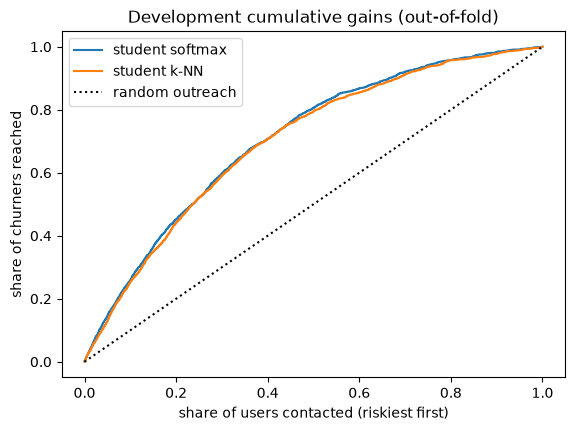

In [8]:
SELECTED = {
    "student softmax": ("softmax", False, "λ=0.1, weights=none"),
    "student k-NN": ("k-NN", False, "k=301"),
}
budget_rows = []
for name, key in SELECTED.items():
    scores = oof[key]
    for budget in (0.10, 0.20, 0.30):
        cut = np.quantile(scores, 1 - budget)
        precision, recall = precision_recall_at(dev_y, scores, cut)
        budget_rows.append({"model": name, "outreach budget": f"top {budget:.0%}",
                            "precision": precision, "recall": recall,
                            "lift vs random": precision / dev_y.mean()})
display(pd.DataFrame(budget_rows).set_index(["model", "outreach budget"]).round(3))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for name, key in SELECTED.items():
    scores = oof[key]
    order = np.argsort(-scores)
    hits = np.cumsum(dev_y.to_numpy()[order])
    ax.plot(np.arange(1, len(scores) + 1) / len(scores), hits / hits[-1], label=name)
ax.plot([0, 1], [0, 1], ":", color="black", label="random outreach")
ax.set(xlabel="share of users contacted (riskiest first)", ylabel="share of churners reached",
       title="Development cumulative gains (out-of-fold)")
ax.legend();

Contacting the riskiest 20% of users reaches about 45% of churners with roughly 40% precision, about 2.3 times better than random outreach. Softmax regression is ahead of k-NN at every budget, though the gap is small.

## 8. One evaluation on the sealed test users

All choices are now frozen. Each selected model is wrapped in `ThresholdedClassifier` with its development threshold, refitted on all 10,724 development users, and scored once on the 3,575 test users through the shared `evaluate_supervised_estimator` boundary. For comparison we also score the baseline and two trusted scikit-learn references (default `LogisticRegression` and brute-force `KNeighborsClassifier` with the same $k$), each with a threshold chosen the same way. Bootstrap intervals (2,000 resamples of test users) show the uncertainty in recall.

In [9]:
final_estimators = {
    "baseline: always retained": (MajorityClassifier(), None),
    "student softmax": (candidates[SELECTED["student softmax"]], oof[SELECTED["student softmax"]]),
    "student k-NN": (candidates[SELECTED["student k-NN"]], oof[SELECTED["student k-NN"]]),
    "reference: sklearn logistic": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=5_000)), None),
    "reference: sklearn k-NN": (
        make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=301, algorithm="brute")),
        None),
}

results, test_rows = {}, []
for name, (estimator, scores) in final_estimators.items():
    if name.startswith("baseline"):
        wrapped = estimator
    else:
        if scores is None:  # references get their own development threshold
            scores = cross_val_predict(estimator, dev_x, dev_y, cv=cv, method="predict_proba")[:, 1]
        threshold = choose_threshold(dev_y, scores, beta=2.0).threshold
        wrapped = ThresholdedClassifier(estimator, threshold=threshold)
    result = evaluate_supervised_estimator(dataset, config, task_name=TASK_KEY,
                                           estimator_name=name, estimator=wrapped)
    results[name] = result
    observed, predicted = result.observed, result.predictions
    probability = (result.estimator.predict_proba(result.holdout_features)[:, 1]
                   if hasattr(result.estimator, "predict_proba") else np.zeros(len(observed)))
    interval = bootstrap_metric_interval(observed, predicted, recall_score)
    test_rows.append({
        "model": name,
        "AP": average_precision_score(observed, probability) if probability.any() else observed.mean(),
        "recall": interval.estimate, "recall 95% CI": f"{interval.lower:.3f}–{interval.upper:.3f}",
        "precision": precision_score(observed, predicted, zero_division=0),
        "F2": fbeta_score(observed, predicted, beta=2),
        "share flagged": predicted.mean(),
    })
display(pd.DataFrame(test_rows).set_index("model").round(3))

,AP,recall,recall 95% CI,precision,F2,share flagged
model,,,,,,
baseline: always retained,0.177,0.000,0.000–0.000,0.000,0.000,0.000
student softmax,0.386,0.855,0.826–0.880,0.270,0.597,0.561
student k-NN,0.366,0.828,0.798–0.855,0.271,0.587,0.542
reference: sklearn logistic,0.387,0.828,0.797–0.856,0.279,0.594,0.526
reference: sklearn k-NN,0.366,0.828,0.798–0.855,0.271,0.587,0.542


**Result.** On users it has never seen, the student softmax model catches about **85% of churners** (95% interval ≈ 83–88%) while flagging about 56% of users, at 27% precision. Its AP (≈0.39) matches the development estimate, so the cross-validated choices were not overfit. Student k-NN is slightly behind on AP, recall, and F2 at about the same precision. Both student models agree with their scikit-learn references (k-NN exactly; logistic regression closely, the small gap coming from different regularization defaults). The baseline catches no churners.

**Practical meaning.** The model is a reasonable *prioritization* tool, not a precise detector: roughly three in four flagged users would have stayed anyway. How useful that is depends on what outreach costs, which is why the budget view matters.

**Comparison with the earlier project.** The earlier tuned, class-weighted XGBoost reported recall 0.58 and precision 0.32 on a different split. At a similar recall (contacting the riskiest 30% of users, §7) the transparent softmax model here reaches precision of about 0.35, so a verified linear model is at least competitive. The splits and procedures differ, so this is indicative only.

## 9. Failure analysis

**What does the model rely on?** The softmax coefficients on standardized features show which behaviors drive the score.

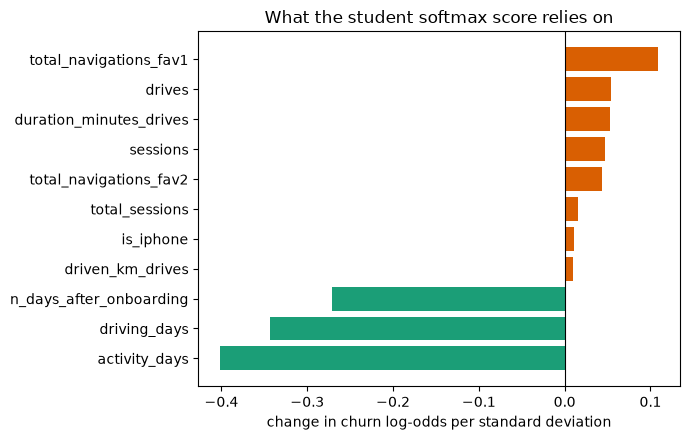

In [10]:
softmax_result = results["student softmax"]
fitted = softmax_result.estimator.estimator_[-1]
log_odds = pd.Series(fitted.coef_[:, 1] - fitted.coef_[:, 0], index=softmax_result.feature_names)
log_odds = log_odds.sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(log_odds.index, log_odds.values,
        color=["#1b9e77" if v < 0 else "#d95f02" for v in log_odds.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="change in churn log-odds per standard deviation",
       title="What the student softmax score relies on")
plt.tight_layout()

The score is dominated by three features: more **active days**, more **driving days**, and longer **tenure** all lower churn risk. Everything else is small: the largest, favorite-place navigations, is about a quarter the size of the active-days effect. (Activity and driving days are strongly correlated, so their split between the two coefficients is not individually meaningful.) This is a readable rule a PM can sanity-check, but it implies an obvious blind spot: a churner who was still active this month looks safe.

In [11]:
holdout = softmax_result.holdout_features.assign(
    churned=softmax_result.observed, flagged=softmax_result.predictions
)
churners = holdout[holdout["churned"] == 1]
by_activity = churners.groupby(pd.cut(churners["activity_days"], [-1, 5, 10, 15, 20, 25, 31]),
                               observed=True)["flagged"].agg(["mean", "size"])
by_activity.columns = ["share of churners caught", "test churners"]
display(by_activity.round(3))

,share of churners caught,test churners
activity_days,,
"(-1, 5]",1.000,245
"(5, 10]",1.000,153
"(10, 15]",0.904,104
"(15, 20]",0.667,66
"(20, 25]",0.167,36
"(25, 31]",0.000,30


**Where it fails.** Recall is essentially 100% for churners active on 10 or fewer days, falls to about two-thirds at 16–20 days, to about one in six at 21–25 days, and to zero above 25 days. About 10% of test churners (66 of 634) were active on more than 20 days, and the model misses nearly all of them. These "active churners" are probably the most valuable to save and the hardest to see, because nothing in one month of usage counts distinguishes them from loyal users.

**Failure sources.**

- *Task formulation (largest):* activity and churn are measured over the same month, so the model mostly detects visible disengagement. Users who leave abruptly while active are invisible. Earlier-window features or event timing would be needed, and this dataset does not have them.
- *Data quality:* implausible speeds in a quarter of rows and inconsistent lifetime totals make distance, duration, and lifetime-session features noisy.
- *Synthetic data:* every pattern here may reflect the generator rather than real users.
- *Implementation:* no defects found. Both student models match trusted references.
- *Drift:* a change in app usage patterns (a feature launch, seasonality) would shift the activity distributions. Input monitoring can detect that; whether the score still ranks well needs delayed churn labels.

## 10. Conclusion and production decision

**Answer.** From one month of usage, a transparent student softmax model ranks Waze users by churn risk about **twice as well as random** (test AP ≈ 0.39 vs 0.18). At the cross-validated F2 threshold it reaches about 85% of churners while contacting about 56% of users; at a 20% outreach budget it reaches about 45% of churners at about 40% precision. Class weighting proved unnecessary once the threshold is tuned.

**Decision.** Keep **student softmax regression ($\lambda = 0.1$, threshold from development data)** as the project's **baseline model to beat**, and as the current promotion candidate for the churn-risk API. Keep k-NN as a comparison. The operating point (F2 threshold versus a fixed outreach budget) is a product decision to confirm with the intended user before deployment.

**Most important limitation.** The model cannot see churners who are still active, and the same-month measurement means these results are not evidence of *early* warning.

**Next steps.**

1. Decision tree (lecture 14), then ensembles (lecture 15). Do non-linear interactions (for example tenure × activity) recover any of the active churners, or only re-rank the obvious ones?
2. Engineered ratio features from the earlier project (for example km per driving day, share of sessions in the last month), implemented and tested in the package.
3. Unsupervised segmentation (k-means and PCA): are there behavioral segments with distinct churn rates that a PM could target differently?
4. Model comparison on development data, then promotion of the winner into the API with input monitoring.